# Playground: report QA, routing and drawing extraction

Everything runs locally (Ollama + bge-m3 + Qdrant embedded).
**Note:** the embedded Qdrant store allows one process at a time. Stop the chat app / CLI before running this
notebook, or set `store.qdrant_url` to a Qdrant server.

Prerequisites: `scripts/setup_ollama.sh` was run and reports were ingested (`docagent ingest data/reports`).

In [1]:
import logging, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image as IPImage

from docagent.config import load_config, PROJECT_ROOT
import os; os.chdir(PROJECT_ROOT)   # all paths below are relative to the project root
from docagent.agent import Agent
from docagent.render import render_markdown

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(name)s: %(message)s")
for n in ("httpx", "httpcore", "openai"): logging.getLogger(n).setLevel(logging.WARNING)

cfg = load_config()            # try variations: cfg.retrieval.top_k = 5, cfg.llm.model = "...", ...
agent = Agent(cfg)
qa = agent.qa                  # loads the embedder + opens the index
print(agent.versions)
print(qa.retriever.store.count(), "chunks:", qa.retriever.store.documents())

W1017 01:56:45.171000 44036 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


2026-10-17 01:56:45,588 docagent.embeddings: loading embedder BAAI/bge-m3 on cpu


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-10-17 01:56:46,924 FlagEmbedding.finetune.embedder.encoder_only.m3.runner: loading existing colbert_linear and sparse_linear---------


pre tokenize:   0%|          | 0/1 [00:00<?, ?it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 427.03it/s]

Inference Embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

Inference Embeddings: 100%|██████████| 1/1 [00:04<00:00,  4.28s/it]

Inference Embeddings: 100%|██████████| 1/1 [00:04<00:00,  4.29s/it]

{'router': 'rules+vlm-v1', 'drawing': 'drawing-read-locate-v2', 'report_qa': 'report-qa-v1', 'llm': 'qwen2.5vl-16k'}
94 chunks: {'ntsb_18-061': 63, 'ntsb_16-006': 25, 'ntsb_24-013': 6}


## 1. Retrieval explorer
What does hybrid search (dense + sparse, RRF fused) return for a query? `via=linked` rows are figures pulled in because a top text hit cites them.

In [2]:
def hits(query, k=8):
    items = qa.retriever.search(query, top_k=k)
    return pd.DataFrame([{
        "score": round(it.score, 3), "via": it.via, "doc": it.chunk.doc_id, "page": it.chunk.page,
        "kind": it.chunk.kind, "fig": it.chunk.figure_no, "text": it.chunk.text[:160]} for it in items])

pd.set_option("display.max_colwidth", 160)
hits("fatigue cracks at bolt holes in the lower spar cap")

,score,via,doc,page,kind,fig,text
0,0.600,hybrid,ntsb_18-061,5,text,NaN,"The right wing main spar lower spar cap piece shown in figure 15 was further examined using an SEM, and resulting images of the reflective area at the forwa..."
1,0.562,hybrid,ntsb_18-061,20,figure,13.0,Figure 13. Optical macrograph of the polished and etched cross-section of the left wing main spar lower spar cap. Etched by immersion in Keller’s reagent.\n...
2,0.450,hybrid,ntsb_18-061,24,figure,17.0,Figure 17. SEM images of a fatigue crack at the lower forward side of the forward hole in the right wing main spar lower spar cap from the accident airplane...
3,0.417,hybrid,ntsb_18-061,23,figure,16.0,Figure 16. SEM image of the fatigue region in the right main spar lower spar cap from the accident airplane (upper image) with a view of the origin area at ...
4,0.383,hybrid,ntsb_18-061,2,text,NaN,"Unlabeled arrows in figure 5 indicate locations of fatigue origins, and dashed lines indicate fatigue boundaries. In the lower spar cap, origins were locate..."
5,0.377,hybrid,ntsb_18-061,4,text,NaN,"To further characterize the origin area at the aft side of hole LC-1, a transverse cut was made through the left wing main spar lower spar cap approximately..."
6,0.343,hybrid,ntsb_18-061,22,figure,15.0,Figure 15. View of the right main spar lower spar cap and doublers from the accident airplane after the crack was opened by lab fracture. The fatigue region...
7,0.292,hybrid,ntsb_18-061,15,figure,7.0,Figure 7. Optical images of fatigue features aft of hole LC-1 including a view of the origin area at higher magnification (lower image). Unlabeled brackets ...


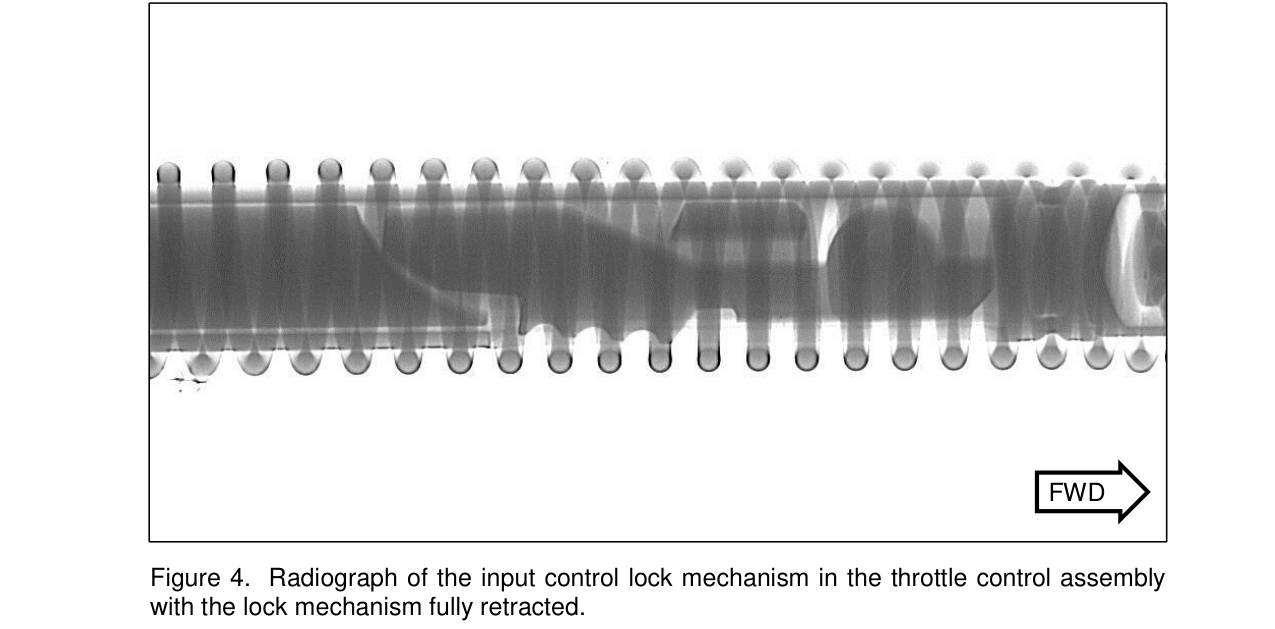

Figure 4. Radiograph of the input control lock mechanism in the throttle control assembly with the lock mechanism fully retracted.
Labels: FWD
Report text citing this figure: Additional x-ray radiographs were taken documenting the input control lock mechanism of the throttle control assembly with the release rod in varying positions as shown in figures 3 and 4. With the release button fully extended, the pawl engaged with the lock coil as shown in the upper image in figure 3. As the release rod was pressed in, the pawl disengaged from the lock coil, and the control was able to move relative to the coil as shown in the lower image in figure 3. The radiograph in figure 4 shows the position of the pawl with the release rod pressed in to its forward limit, and the pawl is retracted further into the control tube as compared to the position shown in the lower image in figure 3. The range of operation of the release rod was measured from the lock position to the full release position. In the 

In [3]:
# look at a retrieved figure crop and what the VLM wrote about it (used for retrieval only)
items = qa.retriever.search("radiograph of the throttle control lock mechanism", top_k=5)
fig = next(it.chunk for it in items if it.chunk.kind == "figure")
display(IPImage(filename=str(PROJECT_ROOT / fig.image_path), width=600))
print(fig.text, "\n\nVLM description:", fig.description)

## 2. Report QA step by step
Observe (pictures) → build query → retrieve → generate. Each step can be swapped or inspected.

In [4]:
question = "What caused the throttle arm to fracture?"
query = qa.build_query(question, observations=[])
items = qa.retrieve(query)
answer = qa.generate(question, items, user_images=[], observations=[])
print(answer.model_dump_json(indent=2, exclude={"retrieved"}))

{
  "answer": "The throttle arm fractured due to bending overstress, as indicated by the examination findings. The threaded section exhibited plastic deformation and there was no evidence of preexisting cracks on the fracture surface.",
  "diagnosis": "The failure is consistent with bending overstress.",
  "recommended_actions": [
    "Inspect similar throttle arms for signs of fatigue or stress concentration at bolt holes.",
    "Ensure proper maintenance procedures are followed to prevent overloading during operation.",
    "Consider conducting a structural analysis if there have been multiple incidents involving this part."
  ],
  "citations": [
    {
      "doc_id": "ntsb_24-013",
      "page": 4,
      "chunk_id": "ntsb_24-013:p4:fig2",
      "figure_no": 2
    },
    {
      "doc_id": "ntsb_24-013",
      "page": 6,
      "chunk_id": "ntsb_24-013:p6:fig5",
      "figure_no": 5
    }
  ],
  "grounded": true,
  "image_observations": []
}


## 3. Full agent: text, picture, or both (routing is automatic)

In [5]:
resp = agent.ask("Why did the left wing main spar fail?")
display(Markdown(render_markdown(resp)))

2026-10-17 01:57:24,168 docagent.pipelines.report_qa: retrieval query: Why did the left wing main spar fail?


The left wing main spar failed due to fatigue cracking. This conclusion is based on several observations from the report and images provided, including the following points from figure 14 in the report ntsb_18-061: 

- The microstructure at the lower surface of the left wing main spar shows features consistent with fatigue fracture.
- The presence of crack arrest lines on the fracture surfaces is indicative of fatigue propagation. 
- The smooth features perpendicular to the longitudinal axis are also characteristic of fatigue cracking, as opposed to ductile overstress fracture which would typically show rough matte-gray features (as seen in figure 2).

The report further supports this conclusion by indicating that the failure originated from a fatigue origin area located in the chamfer between the lower surface and hole LC-1. The crack propagation directions emanating from this origin are also consistent with fatigue fracture, as shown in figures 12 and 14.

Therefore, based on these findings, it is concluded that the left wing main spar failed due to fatigue cracking.

**What is wrong:** Fatigue cracking at a location near hole LC-1.

**What to do** (inferred from the report findings):
- Inspect similar locations on other aircraft parts for signs of fatigue cracks.
- Perform detailed metallographic examinations and hardness tests on critical components to ensure they meet the required standards.

**Sources:** ntsb_18-061 p.21 (Fig. 14)

<sub>request 12d3e1cb1230 · routes: report_qa (rule)</sub>

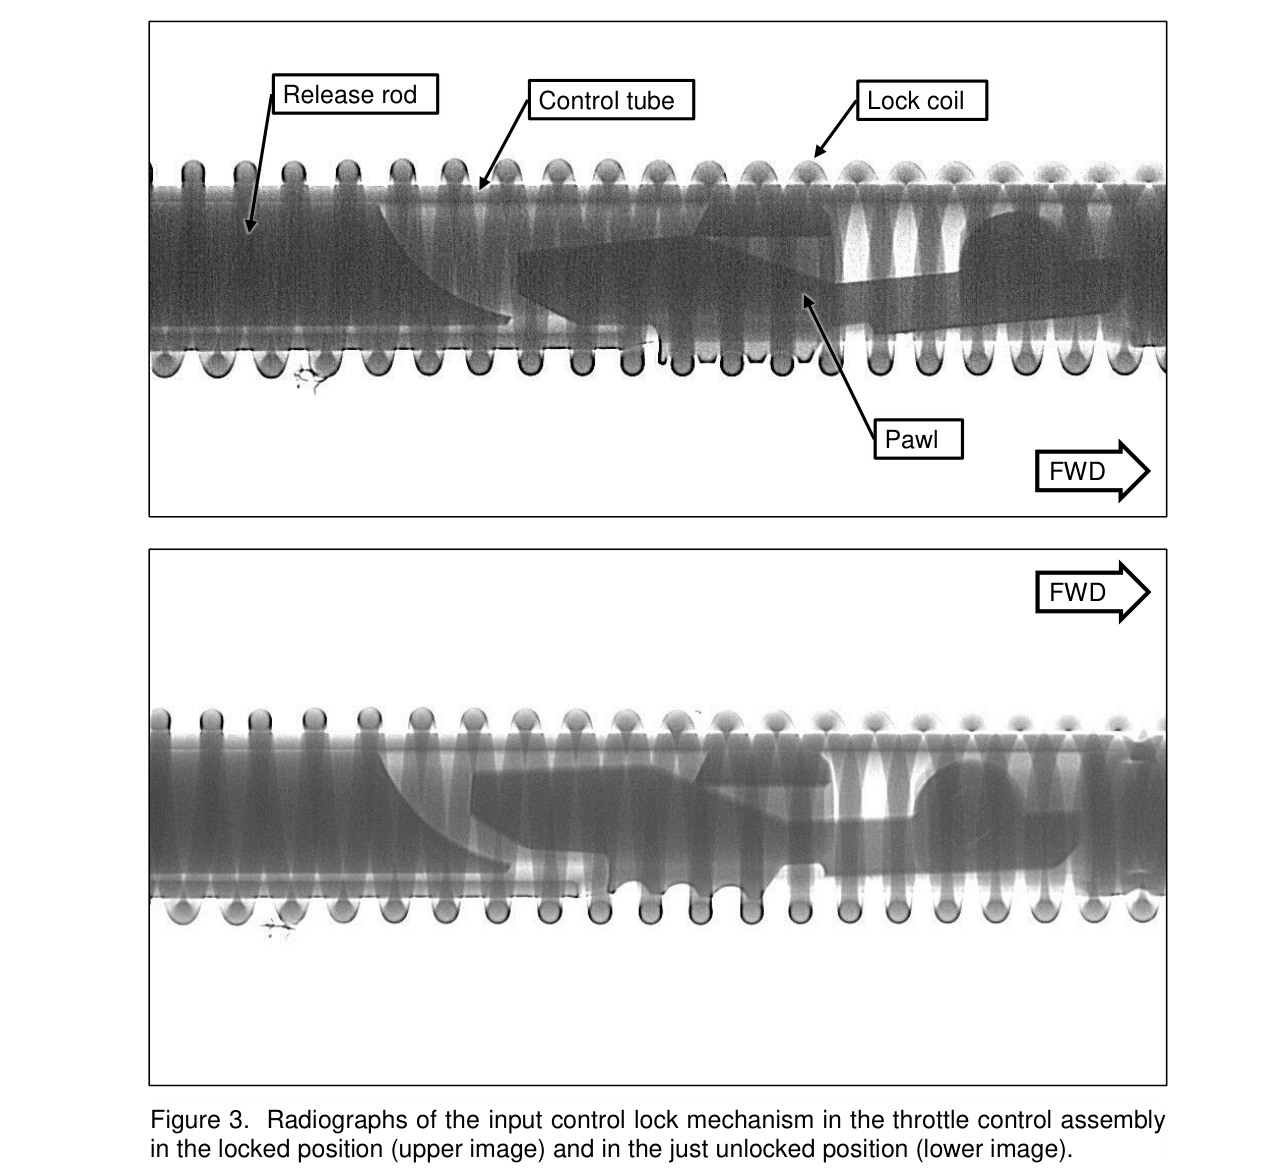

2026-10-17 01:57:35,724 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:57:35,756 docagent.llm: vlm call 11.3s prompt_tokens=1149 completion_tokens=62 images=1


2026-10-17 01:57:52,423 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:57:52,432 docagent.llm: vlm call 16.6s prompt_tokens=1310 completion_tokens=134 images=1


2026-10-17 01:57:52,436 docagent.pipelines.report_qa: retrieval query: input control lock mechanism in the throttle control assembly: The upper image shows the component in a locked position.; The lower image shows the component just after being unlocked.; A release rod is visible at the top left, interacting with the pawl and control tube.; The pawl appears to be enga


2026-10-17 01:58:46,295 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:58:46,307 docagent.llm: vlm call 47.3s prompt_tokens=5890 completion_tokens=177 images=3


_The reports do not clearly cover this; treat the answer with caution._

The radiographs and photographs show that in the locked position of the input control lock mechanism for the throttle control assembly, the pawl engages with the teeth of the control tube. When the component is unlocked, the pawl moves away from its engagement point on the control tube. This indicates normal operation as expected during release. There are no visible signs of fatigue cracking or other material failures in these images.

**What is wrong:** The input control lock mechanism appears to be functioning correctly with no apparent material failure based on the provided radiographs and photographs.

**What to do** (inferred from the report findings):
- Inspect similar throttle control assemblies for wear or damage, focusing particularly at the pawl engagement points.
- Ensure that all release rods are operating within their specified range of motion.

**Sources:** ntsb_16-006 p.8 (Fig. 3)

<sub>request 1da35fecb05e · routes: report_qa (vlm)</sub>

[RouteDecision(route=<Route.REPORT_QA: 'report_qa'>, attachment='store/images/ntsb_16-006/fig3_p8.png', confidence=0.95, tier='vlm', reason='photo_of_part: The image shows radiographs (X-ray images) of an input control lock mechanism in the throttle control assembly, indicating it is a photograph or radiograph of a physical part.')]


In [6]:
# picture only - here a figure crop from a report stands in for a user's photo
photo = "store/images/ntsb_16-006/fig3_p8.png"
display(IPImage(filename=photo, width=500))
resp = agent.ask(None, [photo])
display(Markdown(render_markdown(resp)))
print(resp.routes)

## 4. Routing only

In [7]:
from docagent.schemas import Attachment
files = ["data/drawings/nist_ftc_07_asme1_rd.pdf", "data/reports/ntsb_24-013.pdf", photo]
pd.DataFrame([agent.router.route_attachment(Attachment.from_path(f)).model_dump() for f in files])

2026-10-17 01:58:58,719 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:58:58,730 docagent.llm: vlm call 12.3s prompt_tokens=1168 completion_tokens=57 images=1


,route,attachment,confidence,tier,reason
0,drawing,data/drawings/nist_ftc_07_asme1_rd.pdf,1.00,rule,drawing signals: text_signals=8 landscape=True vector_paths=613 image_coverage=0.00 chars=1284
1,report_qa,data/reports/ntsb_24-013.pdf,0.95,vlm,document_page: The image shows the cover page of a factual report from the National Transportation Safety Board's Materials Laboratory. It includes text and...
2,report_qa,store/images/ntsb_16-006/fig3_p8.png,0.95,vlm,"photo_of_part: The image shows radiographs (X-ray images) of an input control lock mechanism in the throttle control assembly, indicating it is a photograph..."


## 5. Drawing extraction
~3 min per sheet on an M-series Mac (4 tile reads + 1 locate call). Results are cached on disk, so re-running is instant.

In [8]:
ext = agent.drawings.extract("data/drawings/nist_ctc_01_asme1_rd.pdf")
print(ext.units, ext.title_block)
df = pd.DataFrame([v.model_dump(exclude={"bbox"}) for v in ext.values])
df[["page", "type", "raw_text", "nominal", "tol_plus", "tol_minus", "characteristic", "datums",
    "belongs_to", "meaning", "source", "confidence"]]

2026-10-17 01:58:58,867 docagent.pipelines.drawing: nist_ctc_01_asme1_rd sheet 1/1


2026-10-17 01:59:17,341 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:59:17,351 docagent.llm: vlm call 18.4s prompt_tokens=1683 completion_tokens=364 images=1


2026-10-17 01:59:28,901 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 01:59:28,912 docagent.llm: vlm call 11.5s prompt_tokens=1683 completion_tokens=227 images=1


...

2026-10-17 02:00:14,151 docagent.llm: vlm call 22.0s prompt_tokens=1683 completion_tokens=420 images=1


2026-10-17 02:01:11,752 httpx2: HTTP Request: POST http://localhost:11434/v1/chat/completions "HTTP/1.1 200 OK"


2026-10-17 02:01:11,760 docagent.llm: vlm call 57.5s prompt_tokens=2275 completion_tokens=837 images=1


millimeters {'title': 'PMI Complex Test Case 1', 'atomic_test_cases': '1, 2, 3, 4, 7, 8, 17, 21, 33, 48', 'series': 'NIST PMI Test Models - 2012', 'model': 'Test Model 1', 'revision': 'D', 'drawing_number': 'nist_ctc_01_asme1_rd'}


,page,type,raw_text,nominal,tol_plus,tol_minus,characteristic,datums,belongs_to,meaning,source,confidence
0,1,diameter,Ø35.2,35.20,NaN,NaN,NaN,[],left Ø35.2 side hole,Diameter 35.2 millimeters.,vlm,0.6
1,1,diameter,Ø34.8,34.80,NaN,NaN,NaN,[],right Ø34.8 side hole,Diameter 34.8 millimeters.,vlm,0.6
2,1,diameter,Ø20 +0.05,20.00,NaN,NaN,NaN,[],Ø20 +0.05 side hole,Diameter 20 millimeters.,vlm,0.6
3,1,datum_feature,A,NaN,NaN,NaN,NaN,[],A feature,"Identifies this feature as datum A, a reference for GD&T controls.",vlm,0.6
4,1,datum_feature,B,NaN,NaN,NaN,NaN,[],B feature,"Identifies this feature as datum B, a reference for GD&T controls.",vlm,0.6
5,1,tolerance,0.2,0.20,NaN,NaN,NaN,[],0.2 dimension on the side,Size/location dimension 0.2 millimeters.,vlm,0.6
6,1,diameter,Ø0.75,0.75,NaN,NaN,NaN,[],Ø0.75 small hole,Diameter 0.75 millimeters.,vlm,0.6
7,1,gdt_frame,Ø0.75 A B C,0.75,NaN,NaN,straightness,"[A, B, C]",Ø0.75 A B C feature,"Straightness tolerance, cylindrical zone Ø0.75 millimeters relative to datums A, B, C: the line element/axis must lie within this straightness zone.",vlm,0.6
8,1,gdt_frame,Ø0.5 A,0.50,NaN,NaN,-,[A],Ø0.5 A boss,"- tolerance, cylindrical zone Ø0.5 millimeters relative to datums A: the feature must stay within this geometric tolerance.",vlm,0.6
9,1,diameter,Ø25 ±0.15,25.00,0.15,-0.15,NaN,[],Ø25 ±0.15 hole,"Diameter 25 millimeters, tolerance +0.15/-0.15 (acceptable 24.85–25.15 millimeters).",vlm,0.6


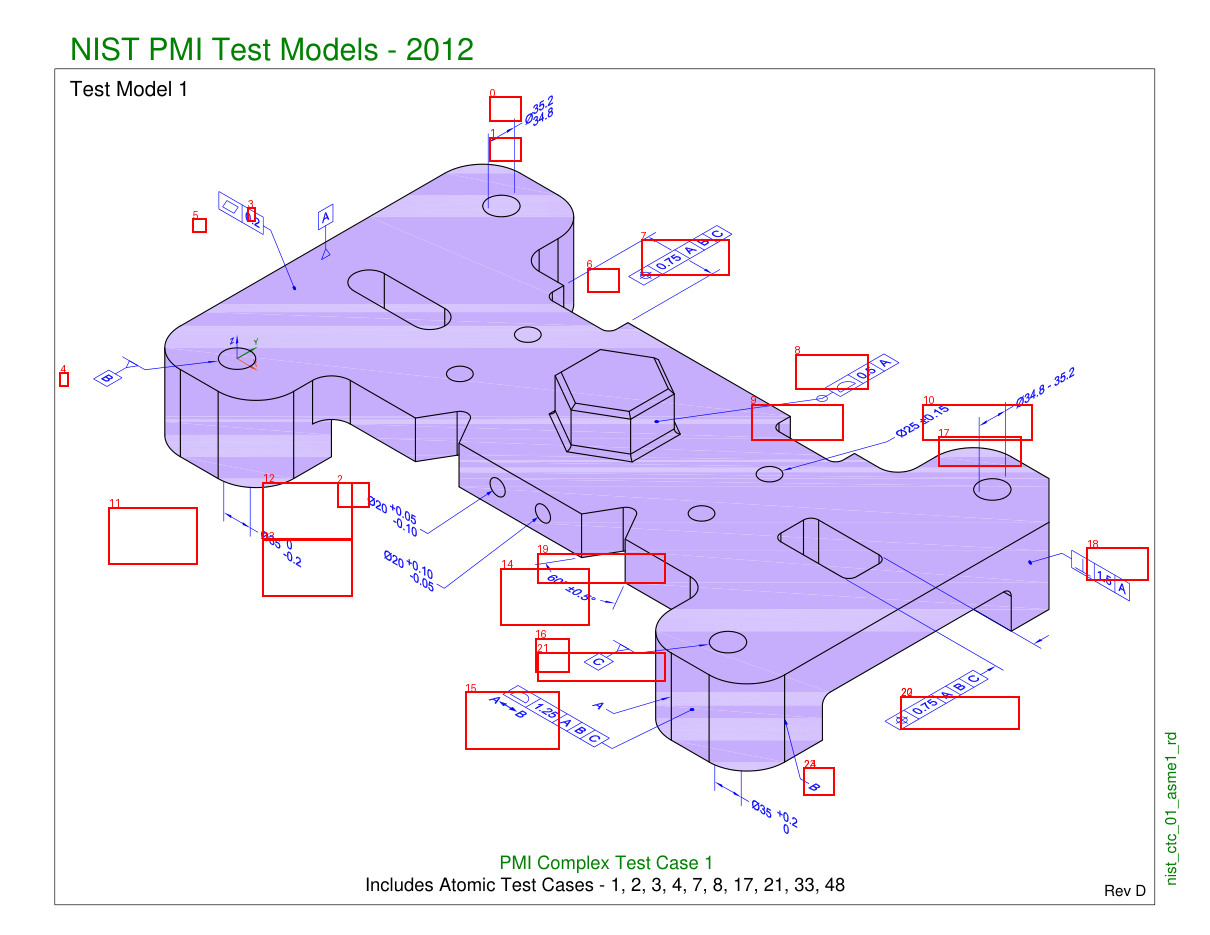

In [9]:
# overlay the extracted boxes on the sheet to eyeball localisation quality
import pymupdf
from PIL import ImageDraw
from docagent.pdf import render
page = pymupdf.open("data/drawings/nist_ctc_01_asme1_rd.pdf")[0]
img = render(page, 110); s = 110 / 72; d = ImageDraw.Draw(img)
for i, v in enumerate(ext.values):
    if v.bbox:
        b = [c * s for c in v.bbox]; d.rectangle(b, outline=(255, 0, 0), width=2); d.text((b[0], b[1] - 10), str(i), fill=(255, 0, 0))
img